In [59]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt


In [60]:
# ------------------ Paths --------------------------
# caravan_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/2_final_runs/1_531_caravan_vs_camels/ensemble_metrics/total_precipitation_sum_seq_270_1_epochs_30_hidden_256_dropout_04_fb_5.csv")
# camels_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/2_final_runs/1_531_caravan_vs_camels/ensemble_metrics/camels_precipitation_seq_270_1_epochs_30_hidden_256_dropout_04_fb_5.csv")
# caravan_peak_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/4_paper/4_precip_analysis/peak_metrics/530_united_states/peak_metrics.csv")

caravan_attributes_dir = Path("/inputs/data_updated_2/attributes/attributes_caravan.csv")
caravan_attributes_2_dir = Path("/inputs/data_updated_2/attributes/attributes_other.csv")
caravan_attributes_3_dir = Path("/inputs/data_updated_2/attributes/attributes_hydroatlas.csv")

caravan_127_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/2_final_runs/2_us_127_basins/ensemble_testing_metrics/total_precipitation_sum_seq_270_1_epochs_30_hidden_256_dropout_04_fb_5.csv")
camels_127_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/2_final_runs/2_us_127_basins/ensemble_testing_metrics/camels_precipitation_seq_270_1_epochs_30_hidden_256_dropout_04_fb_5.csv")
chirps_127_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/2_final_runs/2_us_127_basins/ensemble_testing_metrics/chirps_precipitation_seq_270_1_epochs_30_hidden_256_dropout_04_fb_5.csv")
mswep_127_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/2_final_runs/2_us_127_basins/ensemble_testing_metrics/mswep_precipitation_seq_270_1_epochs_30_hidden_256_dropout_04_fb_5.csv")

peak_metrics_dir = Path("/home/azureuser/NeuralHydrologyAzure/4_paper/4_precip_analysis/peak_metrics/united_states/peak_metrics.csv")


In [61]:
attributes = pd.read_csv(caravan_attributes_dir)
attributes.head()

,gauge_id,aridity_ERA5_LAND,aridity_FAO_PM,frac_snow,high_prec_dur,high_prec_freq,low_prec_dur,low_prec_freq,moisture_index_ERA5_LAND,moisture_index_FAO_PM,p_mean,pet_mean_ERA5_LAND,pet_mean_FAO_PM,seasonality_ERA5_LAND,seasonality_FAO_PM
0,camels_01013500,3.763929,0.492557,0.374538,1.105263,0.047433,2.835099,0.586037,-0.598445,0.537406,3.175454,11.952184,1.564091,0.849594,0.972252
1,camels_01022500,4.539418,0.580916,0.335440,1.083770,0.056674,3.238029,0.638741,-0.716118,0.409718,3.203837,14.543556,1.861159,0.458492,1.187054
2,camels_01030500,4.263635,0.532879,0.316130,1.093123,0.052225,3.029760,0.613210,-0.667997,0.471618,3.184069,13.575707,1.696722,0.632035,1.119152
3,camels_01031500,3.947586,0.510585,0.306273,1.093185,0.053799,3.149326,0.623614,-0.646806,0.495480,3.289056,12.983833,1.679343,0.667906,1.097448
4,camels_01047000,3.694839,0.501584,0.299063,1.100430,0.052498,3.239731,0.626215,-0.628010,0.512243,3.275610,12.102852,1.642993,0.679129,1.047740


In [62]:
attributes_2 = pd.read_csv(caravan_attributes_2_dir)
attributes_2.head()

,gauge_id,gauge_name,country,gauge_lat,gauge_lon,area
0,camels_01013500,"Fish River near Fort Kent, Maine",United States of America,47.23739,-68.58264,2297.683155
1,camels_01022500,"Narraguagus River at Cherryfield, Maine",United States of America,44.60797,-67.93524,619.102595
2,camels_01030500,"Mattawamkeag River near Mattawamkeag, Maine",United States of America,45.50097,-68.30596,3666.943011
3,camels_01031500,"Piscataquis River near Dover-Foxcroft, Maine",United States of America,45.17501,-69.31470,764.824149
4,camels_01047000,"Carrabassett River near North Anson, Maine",United States of America,44.86920,-69.95510,902.895076


In [63]:
attributes_3 = pd.read_csv(caravan_attributes_3_dir)
attributes_3.head()

,gauge_id,sgr_dk_sav,glc_pc_s06,glc_pc_s07,nli_ix_sav,glc_pc_s04,glc_pc_s05,glc_pc_s02,glc_pc_s03,glc_pc_s01,...,dis_m3_pmn,dis_m3_pmx,dis_m3_pyr,lkv_mc_usu,rev_mc_usu,ria_ha_usu,riv_tc_usu,pop_ct_usu,dor_pc_pva,area_fraction_used_for_aggregation
0,camels_01013500,62.866664,83.686013,0.0,224.825073,1.155256,0.0,3.452859,0.0,0.0,...,29.056,96.345,43.627,1626,0,574.366,3455.373,3.768,0,0.990556
1,camels_01022500,36.966994,59.203650,0.0,64.114413,0.000000,0.0,37.562392,0.0,0.0,...,10.668,22.863,14.735,33,0,127.307,536.621,0.397,0,0.977213
2,camels_01030500,35.720051,80.191823,0.0,132.317749,0.127213,0.0,14.337860,0.0,0.0,...,62.116,139.913,79.962,626,116,994.800,7078.501,7.386,46,0.990762
3,camels_01031500,81.916647,28.886132,0.0,259.835094,0.000000,0.0,69.125573,0.0,0.0,...,15.396,32.990,19.704,88,0,172.797,823.769,3.910,0,0.972291
4,camels_01047000,143.513055,15.083741,0.0,372.303975,0.000000,0.0,83.922247,0.0,0.0,...,13.333,45.706,20.694,37,0,208.190,995.284,3.511,0,0.987281


In [64]:
# for column in attributes_3.columns:
#     print(column)

In [65]:
ensemble_metrics = pd.read_csv(caravan_127_metrics_dir)
ensemble_metrics.head()

,basin_id,NSE,MSE,RMSE,KGE,Alpha-NSE,Pearson-r,Beta-KGE,Beta-NSE,FHV,FMS,FLV,Peak-Timing,Missed-Peaks,Peak-MAPE
0,camels_01411300,0.552502,0.616769,0.785346,0.571064,0.659513,0.756664,0.905965,-0.102960,-36.841431,-24.618458,0.302489,0.333333,0.482759,45.911133
1,camels_01466500,0.400847,0.203052,0.450613,0.500515,0.656626,0.652497,0.895974,-0.157760,-35.778008,-22.675110,23.063488,0.181818,0.640000,41.411213
2,camels_01487000,0.478750,0.852170,0.923130,0.678683,0.869900,0.712085,1.058513,0.058398,-19.127542,-9.292469,-70.824371,0.230769,0.320000,34.325642
3,camels_01638480,0.264111,5.679879,2.383250,0.341432,0.568414,0.519057,0.872959,-0.053597,-38.551319,-34.414223,47.016125,0.461538,0.468750,56.510674
4,camels_01644000,0.260570,2.702040,1.643788,0.534352,0.844694,0.578942,1.124171,0.063095,-9.848954,-25.393169,57.781910,0.500000,0.419355,52.703255


In [66]:
ensemble_peak_metrics = pd.read_csv(peak_metrics_dir)
ensemble_peak_metrics = ensemble_peak_metrics.rename(columns={"basin": "basin_id"})
ensemble_peak_metrics.head()

,basin_id,product,peak_timing,missed_peaks
0,camels_01411300,camels,1.240000,0.415094
1,camels_01411300,CARAVAN,1.460000,0.622642
2,camels_01411300,CHIRPS,1.460000,0.433962
3,camels_01411300,MSWEP,1.100000,0.377358
4,camels_01466500,camels,0.931818,0.565217


In [67]:
ensemble_peak_metrics = ensemble_peak_metrics[ensemble_peak_metrics["product"] == "camels"]
ensemble_peak_metrics.head()

,basin_id,product,peak_timing,missed_peaks
0,camels_01411300,camels,1.240000,0.415094
4,camels_01466500,camels,0.931818,0.565217
8,camels_01487000,camels,0.770833,0.428571
12,camels_01638480,camels,0.102041,0.473684
16,camels_01644000,camels,0.314815,0.403509


In [68]:
ensemble_camels_metrics = pd.read_csv(camels_127_metrics_dir)
ensemble_camels_metrics.head()

,basin_id,NSE,MSE,RMSE,KGE,Alpha-NSE,Pearson-r,Beta-KGE,Beta-NSE,FHV,FMS,FLV,Peak-Timing,Missed-Peaks,Peak-MAPE
0,camels_01411300,0.781246,0.301500,0.549090,0.857992,0.917390,0.884493,1.000268,0.000294,-7.962166,-2.289908,36.133907,0.250000,0.379310,25.511459
1,camels_01466500,0.496086,0.170776,0.413250,0.738473,0.969118,0.740831,1.016562,0.025118,0.674076,-1.106751,45.144836,0.454545,0.520000,38.745773
2,camels_01487000,0.673678,0.533490,0.730404,0.774088,0.861306,0.821748,0.994829,-0.005161,-14.178141,-18.380447,-26.520687,0.153846,0.320000,35.895287
3,camels_01638480,0.639758,2.780494,1.667481,0.691879,0.765089,0.800639,0.996762,-0.001366,-21.536013,-18.588890,55.025909,0.153846,0.281250,47.818027
4,camels_01644000,0.693604,1.119639,1.058130,0.751945,1.033165,0.857257,1.200139,0.101696,6.780344,-9.168322,46.795872,0.250000,0.322581,35.065140


In [69]:
ensemble_chirps_metrics = pd.read_csv(chirps_127_metrics_dir)
ensemble_chirps_metrics.head()

,basin_id,NSE,MSE,RMSE,KGE,Alpha-NSE,Pearson-r,Beta-KGE,Beta-NSE,FHV,FMS,FLV,Peak-Timing,Missed-Peaks,Peak-MAPE
0,camels_01411300,0.771753,0.314584,0.560878,0.859203,0.932665,0.880756,1.032722,0.035828,-7.652949,3.038159,29.202089,0.250000,0.413793,21.971931
1,camels_01466500,0.648471,0.119133,0.345156,0.820609,0.983379,0.821423,1.003907,0.005925,-6.222986,-0.538844,5.353490,0.454545,0.480000,27.964207
2,camels_01487000,0.664062,0.549211,0.741088,0.811201,0.970220,0.830411,1.077446,0.077295,-10.327119,-2.080206,-68.198364,0.076923,0.440000,37.451679
3,camels_01638480,0.672797,2.525481,1.589176,0.561206,0.617207,0.857336,0.839821,-0.067577,-38.933853,-27.257215,-411.986115,0.384615,0.375000,48.363785
4,camels_01644000,0.671314,1.201090,1.095943,0.700499,0.778044,0.821878,1.093321,0.047419,-18.247046,-21.117672,-23.413580,0.250000,0.290323,51.106899


In [70]:
ensemble_mswep_metrics = pd.read_csv(mswep_127_metrics_dir)
ensemble_mswep_metrics.head()

,basin_id,NSE,MSE,RMSE,KGE,Alpha-NSE,Pearson-r,Beta-KGE,Beta-NSE,FHV,FMS,FLV,Peak-Timing,Missed-Peaks,Peak-MAPE
0,camels_01411300,0.776035,0.308682,0.555591,0.879810,0.966118,0.884685,1.000026,0.000029,-4.551425,-7.470410,11.167308,0.166667,0.137931,22.776327
1,camels_01466500,0.540986,0.155559,0.394410,0.750370,0.939929,0.757802,1.006849,0.010387,-1.728279,-12.111298,25.677086,0.363636,0.520000,30.937269
2,camels_01487000,0.608887,0.639415,0.799634,0.781549,0.938487,0.794561,1.041613,0.041531,-13.316422,-6.761650,-43.904869,0.076923,0.360000,42.045612
3,camels_01638480,0.704794,2.278517,1.509476,0.700338,0.789249,0.843476,0.855497,-0.060964,-24.946728,-21.676197,-69.845894,0.230769,0.281250,43.281208
4,camels_01644000,0.706895,1.071068,1.034924,0.826541,0.995501,0.853928,1.093438,0.047478,2.146308,-9.963842,-15.355164,0.583333,0.322581,24.396450


In [71]:
merged = (
    ensemble_metrics.filter(["basin_id", "NSE"])  # Use filter instead of [[]]
    .merge(
        ensemble_camels_metrics[["basin_id", "NSE"]],
        on="basin_id",
        how="inner",
        suffixes=("_caravan", "_camels")
    )
    .merge(
        ensemble_peak_metrics[["basin_id", "peak_timing", "missed_peaks"]],
        on="basin_id",
        how="inner",
    )
    .merge(
        attributes[["gauge_id", "frac_snow", "p_mean", "high_prec_dur", "low_prec_dur"]],
        left_on="basin_id",
        right_on="gauge_id",
        how="inner",
    )
    .merge(
        attributes_2[["gauge_id", "area"]],
        on="gauge_id",
        how="inner",
    )
    .merge(
        attributes_3[["gauge_id", "ele_mt_sav"]],
        on="gauge_id",
        how="inner",
    )
)

print(merged.columns.tolist())
merged.head()

['basin_id', 'NSE_caravan', 'NSE_camels', 'peak_timing', 'missed_peaks', 'gauge_id', 'frac_snow', 'p_mean', 'high_prec_dur', 'low_prec_dur', 'area', 'ele_mt_sav']


,basin_id,NSE_caravan,NSE_camels,peak_timing,missed_peaks,gauge_id,frac_snow,p_mean,high_prec_dur,low_prec_dur,area,ele_mt_sav
0,camels_01411300,0.552502,0.781246,1.240000,0.415094,camels_01411300,0.0,3.046962,1.119197,3.687100,79.230476,20.118898
1,camels_01466500,0.400847,0.496086,0.931818,0.565217,camels_01466500,0.0,3.193320,1.107417,3.537472,6.303866,39.641873
2,camels_01487000,0.478750,0.673678,0.770833,0.428571,camels_01487000,0.0,3.132572,1.140236,3.677091,187.283875,16.000000
3,camels_01638480,0.264111,0.639758,0.102041,0.473684,camels_01638480,0.0,2.883632,1.155405,3.756209,233.587289,170.000000
4,camels_01644000,0.260570,0.693604,0.314815,0.403509,camels_01644000,0.0,2.882359,1.146575,3.723380,858.811596,188.050313


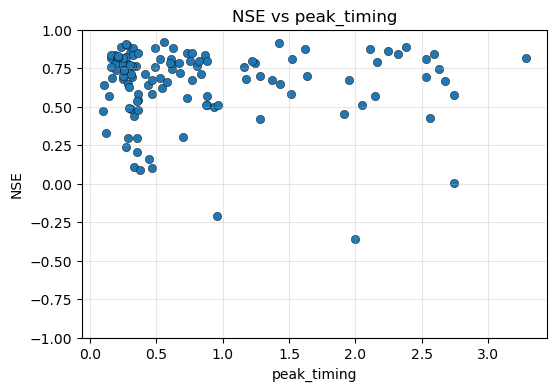

In [72]:
plt.figure(figsize=(6, 4))
sc = plt.scatter(
    merged["peak_timing"],
    merged["NSE_camels"],
    edgecolors="black",
    linewidths=0.3,
)
plt.xlabel("peak_timing")
plt.ylabel("NSE")
plt.title("NSE vs peak_timing")
plt.grid(True, alpha=0.3)
plt.ylim(bottom=-1, top=1)
# plt.colorbar(sc, label="peak_ iming (days)")
plt.show()

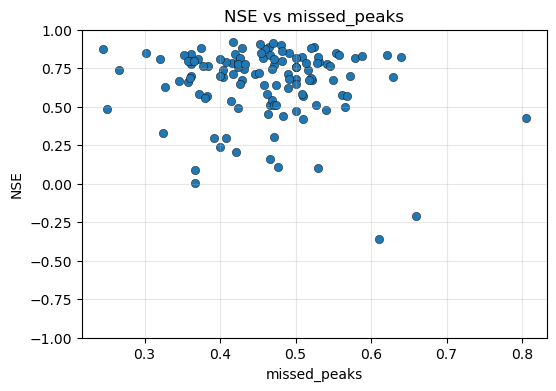

In [73]:
plt.figure(figsize=(6, 4))
sc = plt.scatter(
    merged["missed_peaks"],
    merged["NSE_camels"],
    # c=merged["missed_peaks"],
    # cmap="Blues",
    # alpha=0.7,
    edgecolors="black",
    linewidths=0.3,
)
plt.xlabel("missed_peaks")
plt.ylabel("NSE")
plt.title("NSE vs missed_peaks")
plt.grid(True, alpha=0.3)
plt.ylim(bottom=-1, top=1)
# plt.colorbar(sc, label="fraction of missed peaks")
plt.show()

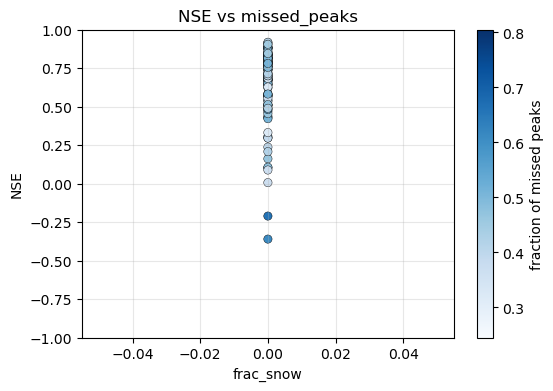

In [74]:
plt.figure(figsize=(6, 4))
sc = plt.scatter(
    merged["frac_snow"],
    merged["NSE_camels"],
    c=merged["missed_peaks"],
    cmap="Blues",
    # alpha=0.7,
    edgecolors="black",
    linewidths=0.3,
)
plt.xlabel("frac_snow")
plt.ylabel("NSE")
plt.title("NSE vs missed_peaks")
plt.grid(True, alpha=0.3)
plt.ylim(bottom=-1, top=1)
plt.colorbar(sc, label="fraction of missed peaks")
plt.show()

In [75]:
# plt.figure(figsize=(6, 4))
# sc = plt.scatter(
#     merged["frac_snow"],
#     merged["NSE"],
#     c=merged["mape_peak"],
#     cmap="Blues",
#     # alpha=0.7,
#     edgecolors="black",
#     linewidths=0.3,
# )
# plt.xlabel("frac_snow")
# plt.ylabel("NSE")
# plt.title("NSE vs frac_snow")
# plt.grid(True, alpha=0.3)
# plt.ylim(bottom=-1, top=1)
# plt.colorbar(sc, label="mape_peak (%)")
# plt.show()

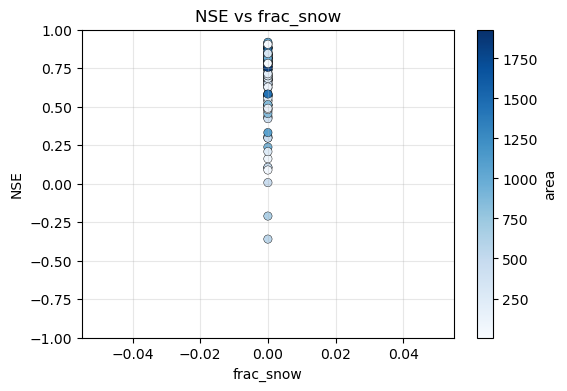

In [76]:
plt.figure(figsize=(6, 4))
sc = plt.scatter(
    merged["frac_snow"],
    merged["NSE_camels"],
    c=merged["area"],
    cmap="Blues",
    # alpha=0.7,
    edgecolors="black",
    linewidths=0.3,
)
plt.xlabel("frac_snow")
plt.ylabel("NSE")
plt.title("NSE vs frac_snow")
plt.grid(True, alpha=0.3)
plt.ylim(bottom=-1, top=1)
plt.colorbar(sc, label="area")
plt.show()


In [77]:
plt.figure(figsize=(6, 4))
sc = plt.scatter(
    merged["frac_snow"],
    merged["NSE"],
    c=merged["ele_mt_sav"],
    cmap="Blues",
    # alpha=0.7,
    edgecolors="black",
    linewidths=0.3,
)
plt.xlabel("frac_snow")
plt.ylabel("NSE")
plt.title("NSE vs frac_snow")
plt.grid(True, alpha=0.3)
plt.ylim(bottom=-1, top=1)
plt.colorbar(sc, label="ele_mt_sav")
plt.show()

KeyError: 'NSE'

<Figure size 600x400 with 0 Axes>

## Correlation matrix

In [ ]:
# import pandas as pd
# import numpy as np

# # Select just the columns you want to correlate
# columns_of_interest = ['NSE', 'frac_snow', 'peak_timing', 'missed_peaks', 'mape_peak']
# correlation_matrix = merged[columns_of_interest].corr()

# print(correlation_matrix)

In [ ]:
# import matplotlib.pyplot as plt
# import seaborn as sns

# # Create heatmap
# sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, square=True)
# plt.tight_layout()
# plt.show()

In [ ]:
# # Remove basins with frac_snow = 0 (or very close to 0)
# merged_filtered = merged[merged['frac_snow'] > 0]

# # Select just the columns you want to correlate
# columns_of_interest = ['NSE', 'frac_snow', 'peak_timing', 'missed_peaks', 'mape_peak']
# correlation_matrix = merged_filtered[columns_of_interest].corr()

# print(correlation_matrix)

# # Create heatmap
# sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, square=True)
# plt.tight_layout()
# plt.show()

In [ ]:
# # Remove basins with frac_snow > 0
# merged_filtered_2 = merged[merged['frac_snow'] == 0]

# # Select just the columns you want to correlate
# columns_of_interest = ['NSE', 'frac_snow', 'peak_timing', 'missed_peaks', 'mape_peak']
# correlation_matrix = merged_filtered_2[columns_of_interest].corr()

# print(correlation_matrix)

# # Create heatmap
# sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', center=0, square=True)
# plt.tight_layout()
# plt.show()

# CAMELS

In [ ]:
merged_camels = (
    ensemble_camels_metrics[["basin_id", "NSE"]]
    .merge(
        attributes[["gauge_id", "frac_snow", "p_mean", "high_prec_dur", "low_prec_dur"]],
        left_on="basin_id",
        right_on="gauge_id",
        how="inner",
    )
    .merge(
        attributes_2[["gauge_id", "area"]],
        on="gauge_id",
        how="inner",
    )
    .merge(
        attributes_3[["gauge_id", "ele_mt_sav"]],
        on="gauge_id",
        how="inner",
    )
    [["basin_id", "NSE", "frac_snow", "p_mean", "high_prec_dur", "low_prec_dur", "area", "ele_mt_sav"]]
)

merged_camels.head()

,basin_id,NSE,frac_snow,p_mean,high_prec_dur,low_prec_dur,area,ele_mt_sav
0,camels_01022500,0.873195,0.335440,3.203837,1.083770,3.238029,619.102595,103.274219
1,camels_01031500,0.888100,0.306273,3.289056,1.093185,3.149326,764.824149,303.634479
2,camels_01047000,0.875006,0.299063,3.275610,1.100430,3.239731,902.895076,378.958111
3,camels_01052500,0.885470,0.368406,3.402069,1.078040,2.515905,395.444910,644.379447
4,camels_01054200,0.657618,0.374272,3.664167,1.104073,2.938824,180.835783,626.000000


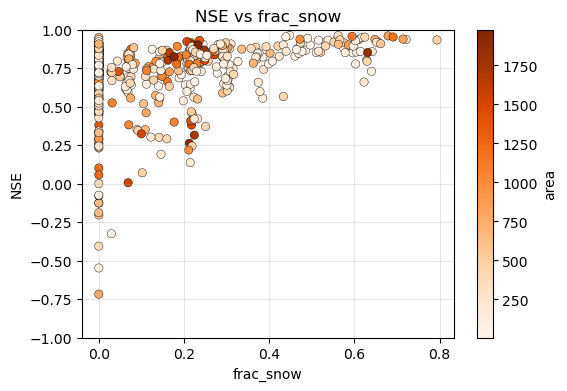

In [ ]:
plt.figure(figsize=(6, 4))
sc = plt.scatter(
    merged_camels["frac_snow"],
    merged_camels["NSE"],
    c=merged_camels["area"],
    cmap="Oranges",
    # alpha=0.7,
    edgecolors="black",
    linewidths=0.3,
)
plt.xlabel("frac_snow")
plt.ylabel("NSE")
plt.title("NSE vs frac_snow")
plt.grid(True, alpha=0.3)
plt.ylim(bottom=-1, top=1)
plt.colorbar(sc, label="area")
plt.show()

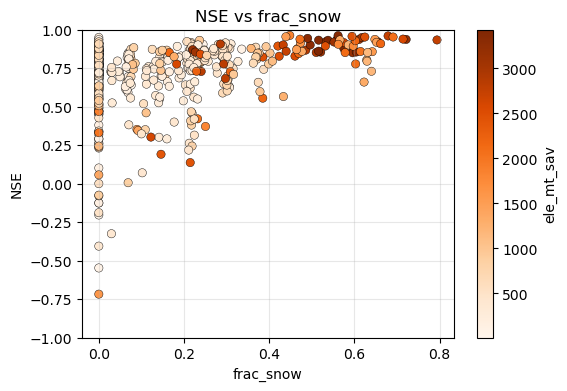

In [ ]:
plt.figure(figsize=(6, 4))
sc = plt.scatter(
    merged_camels["frac_snow"],
    merged_camels["NSE"],
    c=merged_camels["ele_mt_sav"],
    cmap="Oranges",
    # alpha=0.7,
    edgecolors="black",
    linewidths=0.3,
)
plt.xlabel("frac_snow")
plt.ylabel("NSE")
plt.title("NSE vs frac_snow")
plt.grid(True, alpha=0.3)
plt.ylim(bottom=-1, top=1)
plt.colorbar(sc, label="ele_mt_sav")
plt.show()

# CAMELS vs CARAVAN

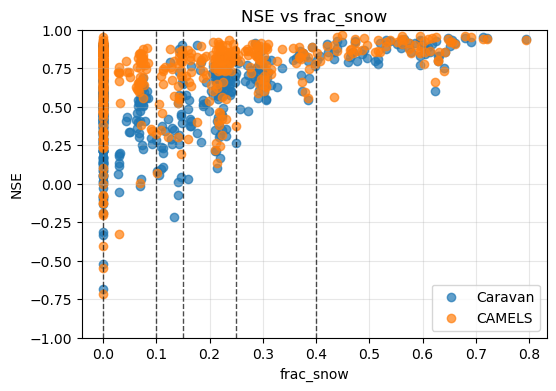

In [ ]:
fig, ax = plt.subplots(figsize=(6, 4))

ax.scatter(merged["frac_snow"], merged["NSE"], alpha=0.7, label="Caravan")
ax.scatter(merged_camels["frac_snow"], merged_camels["NSE"], alpha=0.7, label="CAMELS")

snow_boundaries = snow_bins[:-1]
for boundary in snow_boundaries:
    ax.axvline(boundary, color="black", linestyle="--", linewidth=1, alpha=0.7)

ax.set_xlabel("frac_snow")
ax.set_ylabel("NSE")
ax.set_title("NSE vs frac_snow")
ax.grid(True, alpha=0.3)
ax.set_ylim(-1, 1)
ax.legend()
plt.show()

/tmp/ipykernel_3204/288676369.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats = subset.groupby(bins)["NSE"].quantile([0.25, 0.5, 0.75]).unstack()
/tmp/ipykernel_3204/288676369.py:12: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  stats = subset.groupby(bins)["NSE"].quantile([0.25, 0.5, 0.75]).unstack()


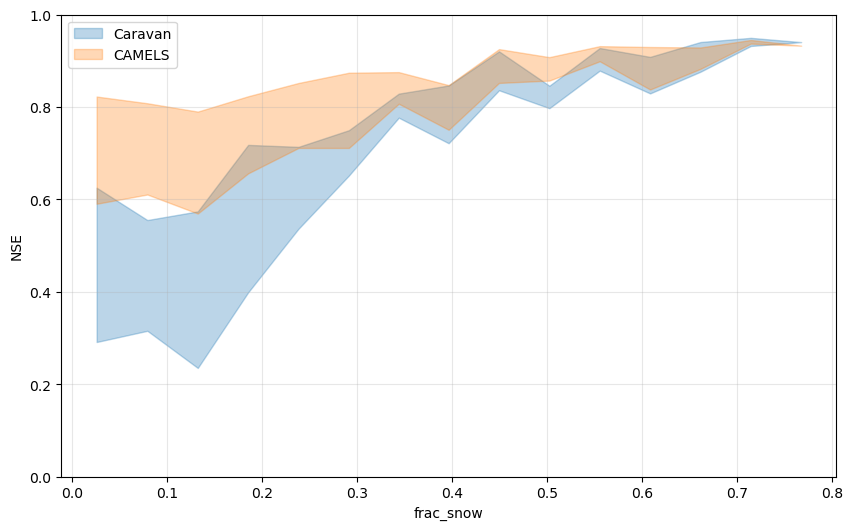

In [ ]:
data = pd.concat([
    merged[["frac_snow", "NSE"]].assign(dataset="Caravan"),
    merged_camels[["frac_snow", "NSE"]].assign(dataset="CAMELS")
])

fig, ax = plt.subplots(figsize=(10, 6))

for dataset, color in [("Caravan", "C0"), ("CAMELS", "C1")]:
    subset = data[data["dataset"] == dataset]
    bins = pd.cut(subset["frac_snow"], bins=15)
    
    stats = subset.groupby(bins)["NSE"].quantile([0.25, 0.5, 0.75]).unstack()
    stats['x'] = stats.index.map(lambda x: x.mid)
    stats = stats.sort_values('x').dropna()
    
    ax.fill_between(stats['x'], stats[0.25], stats[0.75], alpha=0.3, color=color, label=dataset)

ax.set_xlabel("frac_snow")
ax.set_ylabel("NSE")
ax.set_ylim(0, 1)
ax.grid(True, alpha=0.3)
ax.legend()
plt.show()

# Subset US basins

In [ ]:
caravan_127_metrics = pd.read_csv(caravan_127_metrics_dir)
caravan_127_metrics.head()

,basin_id,NSE,MSE,RMSE,KGE,Alpha-NSE,Pearson-r,Beta-KGE,Beta-NSE,FHV,FMS,FLV,Peak-Timing,Missed-Peaks,Peak-MAPE
0,camels_01411300,0.552502,0.616769,0.785346,0.571064,0.659513,0.756664,0.905965,-0.102960,-36.841431,-24.618458,0.302489,0.333333,0.482759,45.911133
1,camels_01466500,0.400847,0.203052,0.450613,0.500515,0.656626,0.652497,0.895974,-0.157760,-35.778008,-22.675110,23.063488,0.181818,0.640000,41.411213
2,camels_01487000,0.478750,0.852170,0.923130,0.678683,0.869900,0.712085,1.058513,0.058398,-19.127542,-9.292469,-70.824371,0.230769,0.320000,34.325642
3,camels_01638480,0.264111,5.679879,2.383250,0.341432,0.568414,0.519057,0.872959,-0.053597,-38.551319,-34.414223,47.016125,0.461538,0.468750,56.510674
4,camels_01644000,0.260570,2.702040,1.643788,0.534352,0.844694,0.578942,1.124171,0.063095,-9.848954,-25.393169,57.781910,0.500000,0.419355,52.703255


In [ ]:
camels_127_metrics = pd.read_csv(camels_127_metrics_dir)
camels_127_metrics.head()

,basin_id,NSE,MSE,RMSE,KGE,Alpha-NSE,Pearson-r,Beta-KGE,Beta-NSE,FHV,FMS,FLV,Peak-Timing,Missed-Peaks,Peak-MAPE
0,camels_01411300,0.781246,0.301500,0.549090,0.857992,0.917390,0.884493,1.000268,0.000294,-7.962166,-2.289908,36.133907,0.250000,0.379310,25.511459
1,camels_01466500,0.496086,0.170776,0.413250,0.738473,0.969118,0.740831,1.016562,0.025118,0.674076,-1.106751,45.144836,0.454545,0.520000,38.745773
2,camels_01487000,0.673678,0.533490,0.730404,0.774088,0.861306,0.821748,0.994829,-0.005161,-14.178141,-18.380447,-26.520687,0.153846,0.320000,35.895287
3,camels_01638480,0.639758,2.780494,1.667481,0.691879,0.765089,0.800639,0.996762,-0.001366,-21.536013,-18.588890,55.025909,0.153846,0.281250,47.818027
4,camels_01644000,0.693604,1.119639,1.058130,0.751945,1.033165,0.857257,1.200139,0.101696,6.780344,-9.168322,46.795872,0.250000,0.322581,35.065140


In [ ]:
chirps_127_metrics = pd.read_csv(chirps_127_metrics_dir)
chirps_127_metrics.head()

,basin_id,NSE,MSE,RMSE,KGE,Alpha-NSE,Pearson-r,Beta-KGE,Beta-NSE,FHV,FMS,FLV,Peak-Timing,Missed-Peaks,Peak-MAPE
0,camels_01411300,0.771753,0.314584,0.560878,0.859203,0.932665,0.880756,1.032722,0.035828,-7.652949,3.038159,29.202089,0.250000,0.413793,21.971931
1,camels_01466500,0.648471,0.119133,0.345156,0.820609,0.983379,0.821423,1.003907,0.005925,-6.222986,-0.538844,5.353490,0.454545,0.480000,27.964207
2,camels_01487000,0.664062,0.549211,0.741088,0.811201,0.970220,0.830411,1.077446,0.077295,-10.327119,-2.080206,-68.198364,0.076923,0.440000,37.451679
3,camels_01638480,0.672797,2.525481,1.589176,0.561206,0.617207,0.857336,0.839821,-0.067577,-38.933853,-27.257215,-411.986115,0.384615,0.375000,48.363785
4,camels_01644000,0.671314,1.201090,1.095943,0.700499,0.778044,0.821878,1.093321,0.047419,-18.247046,-21.117672,-23.413580,0.250000,0.290323,51.106899


In [ ]:
mswep_127_metrics = pd.read_csv(mswep_127_metrics_dir)
mswep_127_metrics.head()

,basin_id,NSE,MSE,RMSE,KGE,Alpha-NSE,Pearson-r,Beta-KGE,Beta-NSE,FHV,FMS,FLV,Peak-Timing,Missed-Peaks,Peak-MAPE
0,camels_01411300,0.776035,0.308682,0.555591,0.879810,0.966118,0.884685,1.000026,0.000029,-4.551425,-7.470410,11.167308,0.166667,0.137931,22.776327
1,camels_01466500,0.540986,0.155559,0.394410,0.750370,0.939929,0.757802,1.006849,0.010387,-1.728279,-12.111298,25.677086,0.363636,0.520000,30.937269
2,camels_01487000,0.608887,0.639415,0.799634,0.781549,0.938487,0.794561,1.041613,0.041531,-13.316422,-6.761650,-43.904869,0.076923,0.360000,42.045612
3,camels_01638480,0.704794,2.278517,1.509476,0.700338,0.789249,0.843476,0.855497,-0.060964,-24.946728,-21.676197,-69.845894,0.230769,0.281250,43.281208
4,camels_01644000,0.706895,1.071068,1.034924,0.826541,0.995501,0.853928,1.093438,0.047478,2.146308,-9.963842,-15.355164,0.583333,0.322581,24.396450


In [ ]:
nse_comparison = (
    caravan_127_metrics[["basin_id", "NSE"]]
    .rename(columns={"NSE": "NSE_caravan"})
    .merge(
        camels_127_metrics[["basin_id", "NSE"]].rename(columns={"NSE": "NSE_camels"}),
        on="basin_id",
        how="outer",
    )
    .merge(
        chirps_127_metrics[["basin_id", "NSE"]].rename(columns={"NSE": "NSE_chirps"}),
        on="basin_id",
        how="outer",
    )
    .merge(
        mswep_127_metrics[["basin_id", "NSE"]].rename(columns={"NSE": "NSE_mswep"}),
        on="basin_id",
        how="outer",
    )
    .merge(
        attributes[["gauge_id", "p_mean"]],
        left_on="basin_id",
        right_on="gauge_id",
        how="left",
    )
    .drop(columns="gauge_id")
    .merge(
        attributes_2[["gauge_id", "area"]],
        left_on="basin_id",
        right_on="gauge_id",
        how="left",
    )
    .drop(columns="gauge_id")
    .merge(
        attributes_3[["gauge_id", "ele_mt_sav"]],
        left_on="basin_id",
        right_on="gauge_id",
        how="left",
    )
    .drop(columns="gauge_id")
)

nse_comparison.head()
# nse_comparison.shape

,basin_id,NSE_caravan,NSE_camels,NSE_chirps,NSE_mswep,p_mean,area,ele_mt_sav
0,camels_01411300,0.552502,0.781246,0.771753,0.776035,3.046962,79.230476,20.118898
1,camels_01466500,0.400847,0.496086,0.648471,0.540986,3.193320,6.303866,39.641873
2,camels_01487000,0.478750,0.673678,0.664062,0.608887,3.132572,187.283875,16.000000
3,camels_01638480,0.264111,0.639758,0.672797,0.704794,2.883632,233.587289,170.000000
4,camels_01644000,0.260570,0.693604,0.671314,0.706895,2.882359,858.811596,188.050313


In [ ]:
plot_data = nse_comparison.melt(
    id_vars=["basin_id", "p_mean", "area", "ele_mt_sav"],
    value_vars=["NSE_caravan", "NSE_camels", "NSE_chirps", "NSE_mswep"],
    var_name="dataset",
    value_name="NSE",
)

plot_data["dataset"] = plot_data["dataset"].str.replace("NSE_", "", regex=False).str.upper()

In [ ]:
products = [('CARAVAN', 'C0'), ('CAMELS', 'C1'), ('CHIRPS', 'C2'), ('MSWEP', 'C3')]

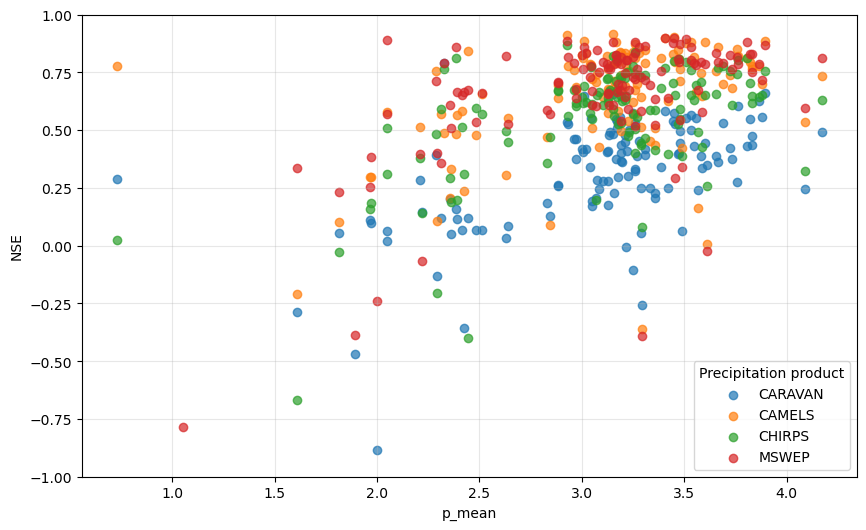

In [ ]:
fig, ax = plt.subplots(figsize=(10, 6))

for dataset, color in products:
    subset = plot_data[plot_data["dataset"] == dataset]
    ax.scatter(
        subset["p_mean"],
        subset["NSE"],
        alpha=0.7,
        color=color,
        label=dataset,
    )

ax.set_xlabel("p_mean")
ax.set_ylabel("NSE")
ax.set_ylim(-1, 1)
ax.grid(True, alpha=0.3)
ax.legend(title="Precipitation product")
plt.show()